# Simulator definition

#1 Split training dataset and recorded data
#2 Get odom data for recorded data
#3 Change and make sure the ipynb graphs are correct

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

# General Params
dt = 0.01
k0 = 0.8
delta = 0.1
ambivalence = 0.0
avoidance = 0.0
epsilon = 1.0
# Impulse parameters
amplitude = 0.0
tdiff = 2.0

# Ambivalence
# Best yet - resultant unnormalized
# amplitude = 1.5
# tdiff = 2.0
# Best - tangential
# amplitude = 0.5
# tdiff = 1.0
b = 0.5
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
import os
import glob


def _merge_child_parent_data(child_data, parent_data):
    """Merge child and parent data dictionaries intelligently.
    
    For keys present in both, prefer parent data.
    For keys present in only one, use that data.
    """
    merged_data = {}
    all_keys = set(child_data.keys()) | set(parent_data.keys())
    
    for key in all_keys:
        child_val = child_data.get(key, [])
        parent_val = parent_data.get(key, [])
        
        if child_val and not parent_val:
            merged_data[key] = child_val
        elif parent_val and not child_val:
            merged_data[key] = parent_val
        elif child_val and parent_val:
            merged_data[key] = parent_val
        else:
            merged_data[key] = []
    
    return merged_data


def _load_experiment_directory(exp_dir):
    """Load and merge child_data.npy and parent_data.npy from experiment directory.
    
    Returns:
        dict: Merged data dictionary, or None if files don't exist
    """
    child_file = os.path.join(exp_dir, "child_data.npy")
    parent_file = os.path.join(exp_dir, "parent_data.npy")
    
    if not os.path.exists(child_file) or not os.path.exists(parent_file):
        return None
    
    child_data = np.load(child_file, allow_pickle=True).item()
    parent_data = np.load(parent_file, allow_pickle=True).item()
    
    return _merge_child_parent_data(child_data, parent_data)


def _print_data_summary(data, experiment_path):
    """Print summary information about loaded data."""
    print(f"Loaded data from {experiment_path}")
    print(f"  - Total timesteps: {len(data.get('ambivalence', []))}")
    
    if data.get('ambivalence'):
        print(f"  - Ambivalence: {data['ambivalence'][0]}")
    if data.get('avoidance'):
        print(f"  - Avoidance: {data['avoidance'][0]}")


def _parameters_match(data, ambivalence, avoidance, tolerance):
    """Check if data parameters match target values within tolerance."""
    data_ambivalence = data.get('ambivalence', [None])[0] if data.get('ambivalence') else None
    data_avoidance = data.get('avoidance', [None])[0] if data.get('avoidance') else None
    
    if ambivalence is not None:
        if data_ambivalence is None or abs(data_ambivalence - ambivalence) > tolerance:
            return False
    
    if avoidance is not None:
        if data_avoidance is None or abs(data_avoidance - avoidance) > tolerance:
            return False
    
    return True


def _get_search_directory(experiment_path):
    """Determine the base directory for searching experiment data."""
    if experiment_path is None:
        return os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "data")
    elif os.path.isfile(experiment_path):
        return os.path.dirname(experiment_path)
    else:
        return experiment_path


def load_data_struct(experiment_path=None, ambivalence=None, avoidance=None, tolerance=0.01):
    """Load child and parent .npy files from the experiment directory.
    
    Args:
        experiment_path: Path to specific experiment directory, or base data directory to search in.
                        If None, searches in ../data/
        ambivalence: Target ambivalence value to search for (optional)
        avoidance: Target avoidance value to search for (optional)
        tolerance: Tolerance for matching parameter values (default: 0.01)
        
    Returns:
        dict: Merged data dictionary with combined data from child and parent files
        
    Raises:
        FileNotFoundError: If experiment directory or data files not found
        ValueError: If experiment_path is not a directory
    """
    # Case 1: Load from specific path without parameter search
    if experiment_path and ambivalence is None and avoidance is None:
        if not os.path.isdir(experiment_path):
            raise ValueError(f"Path must be a directory: {experiment_path}")
        
        data = _load_experiment_directory(experiment_path)
        if data is None:
            raise FileNotFoundError(f"Missing child_data.npy or parent_data.npy in: {experiment_path}")
        
        _print_data_summary(data, experiment_path)
        return data
    
    # Case 2: Search for experiment matching parameters
    base_dir = _get_search_directory(experiment_path)
    exp_dirs = glob.glob(os.path.join(base_dir, "experiment_data_*"))
    
    if not exp_dirs:
        raise FileNotFoundError(f"No experiment directories found in: {base_dir}")
    
    print(f"Searching {len(exp_dirs)} experiment directories for matching parameters...")
    
    for exp_dir in sorted(exp_dirs):
        data = _load_experiment_directory(exp_dir)
        if data is None:
            continue
        
        if not _parameters_match(data, ambivalence, avoidance, tolerance):
            continue
        
        # Found a match!
        print(f"\n✓ Found matching data in {os.path.basename(exp_dir)}")
        data_ambivalence = data.get('ambivalence', [None])[0] if data.get('ambivalence') else None
        data_avoidance = data.get('avoidance', [None])[0] if data.get('avoidance') else None
        print(f"  - Ambivalence: {data_ambivalence}")
        print(f"  - Avoidance: {data_avoidance}")
        print(f"  - Total timesteps: {len(data.get('ambivalence', []))}")
        
        return data
    
    # No match found
    raise FileNotFoundError(
        f"No experiment found with ambivalence={ambivalence}, avoidance={avoidance} "
        f"(tolerance={tolerance}) in {base_dir}"
    )

In [3]:
# Load experimental data examples

# Example 1: Load by avoidance parameter
try:
    print("=" * 60)
    print("Example: Loading data with avoidance = 0.1")
    print("=" * 60)
    loaded_data_avoidance = load_data_struct(avoidance=0.1)
    print("\nData structure keys:", list(loaded_data_avoidance.keys()))
except FileNotFoundError as e:
    print(f"Error: {e}")

# Example 2: Load by ambivalence parameter
try:
    print("\n" + "=" * 60)
    print("Example: Loading data with ambivalence = 0.5")
    print("=" * 60)
    loaded_data_ambivalence = load_data_struct(ambivalence=0.5)
    print("\nData structure keys:", list(loaded_data_ambivalence.keys()))
except FileNotFoundError as e:
    print(f"Error: {e}")

# Example 3: Load specific experiment directory
try:
    print("\n" + "=" * 60)
    print("Example: Loading from experiment_data_0")
    print("=" * 60)
    base_dir = os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "data")
    exp_dir = os.path.join(base_dir, "experiment_data_0")
    loaded_data_struct = load_data_struct(exp_dir)
    print("\nData structure keys:", list(loaded_data_struct.keys()))
except FileNotFoundError as e:
    print(f"Error: {e}")

Example: Loading data with avoidance = 0.1
Searching 34 experiment directories for matching parameters...

✓ Found matching data in experiment_data_1
  - Ambivalence: 0.0
  - Avoidance: 0.1
  - Total timesteps: 1761

Data structure keys: ['child_evidence_trace', 'vocal_child', 'Xc', 'child_states', 'vocal_parent', 'physical_coupling_targets', 'Xp', 'parent_evidence_trace', 'ambivalence', 'avoidance', 'emotional_coupling_targets', 'parent_states']

Example: Loading data with ambivalence = 0.5
Searching 34 experiment directories for matching parameters...

✓ Found matching data in experiment_data_13
  - Ambivalence: 0.5
  - Avoidance: 0.0
  - Total timesteps: 1760

Data structure keys: ['child_evidence_trace', 'vocal_child', 'Xc', 'child_states', 'vocal_parent', 'physical_coupling_targets', 'Xp', 'parent_evidence_trace', 'ambivalence', 'avoidance', 'emotional_coupling_targets', 'parent_states']

Example: Loading from experiment_data_0
Loaded data from /root/pkgs/mdk-230105/catkin_ws/src/

## Child and parent classes

In [4]:
class Child ():
    def __init__(self, child0, physical_coupling = None, emotional_coupling = None):
      self.xc = child0[0]
      self.yc = child0[1]
      self.t_last = 0
      self.ambivalence = ambivalence
      self.avoidance = avoidance
      self.amplitude = amplitude

      self.call_trace = np.array([])
      self.evidence_trace = np.array([])
      self.kp = 0.1
      self.ke = 0.1
      self.kappa = 0.2
      self.physical_coupling = physical_coupling
      self.emotional_coupling = emotional_coupling

    def step( self, t, parent_state, parent_vocalization, distance ):


      prev_call_trace = self.call_trace[-1] if len(self.call_trace) > 0 else 0.0
      prev_evidence    = self.evidence_trace[-1] if len(self.evidence_trace) > 0 else 0.0

      # probability of a new spontaneous call
      p_call = max(0.0, 1.0 - prev_call_trace)

      self_vocal = 0
      if self.xc > 0 and np.random.rand() < p_call:
          self_vocal = 1

      # OR force call when child vocalizes (if you want that)
      if parent_vocalization and self.xc > 0:
          self_vocal = 1

      new_call_trace = (1 - self.kp) * prev_call_trace + self.kappa * self_vocal
      self.call_trace = np.append(self.call_trace, new_call_trace)


      # Update evidence: child vocal *previous* pending trace
      new_evidence = (1 - self.ke) * prev_evidence + self.kappa * parent_vocalization * prev_call_trace
      self.evidence_trace = np.append(self.evidence_trace, new_evidence)

      self.xp = parent_state[0]
      self.yp = parent_state[1]

      # Couplings - physical
      if self.physical_coupling is not None:
          input = torch.tensor( [distance, self.xc, self.yc, self.ambivalence] ).float().to(device)
          p_coupling = self.physical_coupling( input ).item()
      else:
          p_coupling = (self.yc + self.yp)/2 + self.yc

      # Couplings - emotional
      if self.emotional_coupling is not None:
          input = torch.tensor( [self.evidence_trace[-1], 
                                 parent_vocalization, 
                                 self_vocal,
                                 self.xc,
                                 self.yc,
                                 self.avoidance
                                 ] ).float().to(device)
          e_coupling = self.emotional_coupling( input ).item()
      else:
          e_coupling = k0*((self.yc - self.yp)/2 + self.yc) + delta*k0
    

      self.xc = self.xc + dt*(self.xc - 2*self.xc**3 - self.yc)
      self.yc = self.yc + epsilon*dt*(
                                      b*self.xc -
                                      self.ambivalence*p_coupling -
                                      self.avoidance*e_coupling)

      return np.array([self.xc, self.yc]), \
             np.heaviside(self.xc, 0), \
             self_vocal

class Parent ():
    def __init__(self, parent0, physical_coupling = None, emotional_coupling = None):
      self.xp = parent0[0]
      self.yp = parent0[1]
      self.t_last = 0
      self.ambivalence = ambivalence
      self.avoidance = avoidance
      self.amplitude = amplitude

      self.kp = 0.1
      self.ke = 0.1
      self.kappa = 0.2
      self.call_trace = np.array([])
      self.evidence_trace = np.array([])

      self.physical_coupling = physical_coupling
      self.emotional_coupling = emotional_coupling

    def step( self, t, child_state, child_vocalization, distance ):


      self.xc = child_state[0]
      self.yc = child_state[1]

      prev_call_trace = self.call_trace[-1] if len(self.call_trace) > 0 else 0.0
      prev_evidence    = self.evidence_trace[-1] if len(self.evidence_trace) > 0 else 0.0

      # probability of a new spontaneous call
      p_call = max(0.0, 1.0 - prev_call_trace)


      self_vocal = 0
      if self.xp > 0 and np.random.rand() < p_call:
          self_vocal = 1

      # OR force call when child vocalizes (if you want that)
      if child_vocalization and self.xp > 0:
          self_vocal = 1

      new_call_trace = (1 - self.kp) * prev_call_trace + self.kappa * self_vocal
      self.call_trace = np.append(self.call_trace, new_call_trace)

      # Update evidence: child vocal *previous* pending trace
      new_evidence = (1 - self.ke) * prev_evidence + self.kappa * child_vocalization * prev_call_trace
      self.evidence_trace = np.append(self.evidence_trace, new_evidence)

      # Couplings - physical
      if self.physical_coupling is not None:
          input = torch.tensor( [distance, 
                                 self.xp, 
                                 self.yp, 
                                 self.ambivalence] ).float().to(device)
          p_coupling = self.physical_coupling( input ).item()
      else:
          p_coupling = (self.yc + self.yp)/2 + self.yc

      # Couplings - emotional
      if self.emotional_coupling is not None:
          input = torch.tensor( [self.evidence_trace[-1], 
                                 child_vocalization, 
                                 self_vocal,
                                 self.xp,
                                 self.yp,
                                 self.avoidance
                                 ] ).float().to(device)
          e_coupling = self.emotional_coupling( input ).item()
      else:
          e_coupling = k0*((self.yc - self.yp)/2 + self.yc) + delta*k0

      self.xp = self.xp + dt*(self.xp - 2*self.xp**3 - self.yp )
      self.yp = self.yp + epsilon*dt*(
                                      b*self.xp +
                                      self.ambivalence*p_coupling -
                                      self.avoidance*e_coupling)

      physical_coupling_targets = np.array( (self.yc + self.yp)/2 + self.yc)
      emotional_coupling_targets = np.array( k0*((self.yc - self.yp)/2 + self.yc) + delta*k0 )

      return np.array([self.xp, self.yp]), \
             np.heaviside(self.xp, 0), \
             self_vocal, \
             physical_coupling_targets, \
             emotional_coupling_targets

## Agent simulator

In [5]:
class Simulator:
  def __init__(self, bounds = [-1, 1, -1, 1], dx = 0.07, dt = 0.01):
    self.parent = np.array([0, 0])
    self.child = np.array([0.0, 0.0])
    self.time = 0.0
    self.dx = dx
    self.dt = dt
    self.bounds = bounds
    self.ngoal = np.array([1.0, 1.0])

  def physical_distance(self):
    distance = np.sqrt(np.linalg.norm(self.parent - self.child))
    return distance

  def reset(self):
    self.parent = np.array([0.0, 0.0])
    self.child = np.random.rand(2)*2 - 1

  def step( self, parent_command, child_command ):
    '''
      Performs one simulation step and returns the positions of the agents
      - parent_command 1 - approach, 0- avoid
      - child_command 1 - approach, 0 - avoid
      - return: pos: {parent: [x,y], child: [x, y]}
    '''
    # if parent_command:
    vp = (np.array([0.0, 0.0]) - self.parent) + (np.random.rand(2)*2 - 1)*0.1
    # else:
    #   vp = (np.ones(2) - self.parent) + (np.random.rand(2)*2 - 1)*0.5

    if child_command:
      vc = -(self.child - self.parent) + (np.random.rand(2)*2 - 1)*0.5
      self.ngoal = np.sign(np.random.rand(2)-0.5)+ (np.random.rand(2)*2 - 1)*0.5
    else:
      vc = (self.ngoal - self.child) + (np.random.rand(2)*2 - 1)*0.5

    vp /= np.linalg.norm(vp)
    vc /= np.linalg.norm(vc)

    self.parent += self.dx*vp

    if np.linalg.norm(self.child + self.dx*vc, ord = 1) < 0.1:
      vc = -vc

    self.child += self.dx*vc
    self.time += self.dt

    parent = self.bound(self.parent)
    child = self.bound(self.child)

    return {"parent": self.parent, "child": self.child}

  def bound( self, agent ):
    if agent[0] < self.bounds[0]:
      agent[0] = self.bounds[0]

    if agent[0] > self.bounds[1]:
      agent[0] = self.bounds[1]

    if agent[1] < self.bounds[2]:
      agent[1] = self.bounds[2]

    if agent[1] > self.bounds[3]:
      agent[1] = self.bounds[3]

    return agent

  def render( self, ax ):
    '''
      Renders the simulator
    '''
    ax.plot(self.parent[0], self.parent[1], 'k.', markersize = 15)
    ax.plot(self.child[0], self.child[1], 'b.', markersize = 15)

    ax.plot([self.bounds[0], self.bounds[0]], [self.bounds[2], self.bounds[3]], 'k')
    ax.plot([self.bounds[0], self.bounds[1]], [self.bounds[2], self.bounds[2]], 'k')
    ax.plot([self.bounds[1], self.bounds[1]], [self.bounds[2], self.bounds[3]], 'k')
    ax.plot([self.bounds[0], self.bounds[1]], [self.bounds[3], self.bounds[3]], 'k')

In [6]:
T = 10000
N = 5
# Initial conditions

ambivalence = 0.7
avoidance = 0.0

def simulateSS( ambivalence, avoidance, T, physical_parent_coupling = None, emotional_parent_coupling = None, physical_child_coupling = None, emotional_child_coupling = None ):
  sim = Simulator(dx = 0.03, dt = dt)

  child = Child(np.array([1.0, 1.0]), physical_child_coupling, emotional_child_coupling)
  parent = Parent(np.array([-1.0, -0.3]), physical_parent_coupling, emotional_parent_coupling)
  child.avoidance = avoidance
  parent.avoidance = avoidance
  child.ambivalence = ambivalence
  parent.ambivalence = ambivalence
  child.amplitude = amplitude
  parent.amplitude = amplitude

  sim.reset()

  Xp = np.zeros((2, T))
  Xc = np.zeros((2, T))

  child_history = np.zeros((2, T))
  vocal_parent_history = np.zeros(T)
  parent_history = np.zeros((2, T))
  vocal_child_history = np.zeros(T)

  p_target_history = np.zeros((1, T))
  e_target_history = np.zeros((1, T))

  distance_history = np.zeros(T)
  # obs_history = np.zeros(T)
  parent_state = np.zeros(2)
  time = np.zeros(T)
  vocal_parent_prev, vocal_child_prev = 0, 0

  for i in range(T):
      child_state, action_child, vocal_child = child.step( sim.time, parent_state, vocal_parent_prev, sim.physical_distance() )
      parent_state, action_parent, vocal_parent, \
      physical_coupling_targets, emotional_coupling_targets  = parent.step( sim.time, child_state, vocal_child_prev, sim.physical_distance() )
      vocal_parent_prev = vocal_parent
      vocal_child_prev = vocal_child

      # Saving state child
      child_history[:, i] = child_state
      # Saving state parent
      parent_history[:, i] = parent_state
      vocal_child_history[i] = int(vocal_child)
      vocal_parent_history[i] = int(vocal_parent)
      distance_history[i] = sim.physical_distance()

      pos = sim.step(action_parent, action_child)

      Xp[:, i] = pos["parent"]
      Xc[:, i] = pos["child"]

      p_target_history[:, i] = physical_coupling_targets
      e_target_history[:, i] = emotional_coupling_targets
      time[i] = sim.time
  
  amb_array = [ambivalence]*T
  av_array = [avoidance]*T

  data_struct = {
      'Xc': Xc,
      'Xp': Xp,
      'ambivalence': amb_array,
      'avoidance': av_array,
      'physical_coupling_targets': p_target_history,
      'emotional_coupling_targets': e_target_history,
      'child_states': child_history,
      'parent_states': parent_history,
      'vocal_child': vocal_child_history,
      'vocal_parent': vocal_parent_history,
      'child_object': child,
      'parent_object': parent
  }
  print(data_struct)
  return data_struct

## Network training

In [7]:
# Attachment dataset for the physical distance task
class AttachmentPhysicalDataset(torch.utils.data.Dataset):
    def __init__(self, X, Y, window_size = 20):
      super(AttachmentPhysicalDataset, self).__init__()
      # Cast to torch.float32 during initialization
      self.X = X
      self.Y = Y

      self.window = window_size
      self.num_traj, self.T_total, _ = X.shape

      # build list of (traj_id, start)
      self.index_list = []
      for traj_id in range(self.num_traj):
          for start in range(self.T_total - window_size):
              self.index_list.append((traj_id, start))

    def __len__(self):
        return len(self.index_list)

    def __getitem__(self, idx):
        traj_id, start = self.index_list[idx]

        x_seq = self.X[traj_id, start:start+self.window, :]  # [T_window, D_in]
        y_seq = self.Y[traj_id, start:start+self.window, :]  # [T_window, D_out]

        return x_seq, y_seq

class EvaluationDataset(torch.utils.data.Dataset):
    def __init__(self, X, Y, window_size = 20):
      super(EvaluationDataset, self).__init__()
      # Cast to torch.float32 during initialization
      self.X = X
      self.Y = Y

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        x = self.X[idx, :, :].squeeze(0)
        y = self.Y[idx, :, :].squeeze(0)

        return x, y

# Attachment dataset for the emotional distance task
class AttachmentEmotionalDataset(torch.utils.data.Dataset):
    def __init__(self, X, Y, window_size = 20):
      super(AttachmentEmotionalDataset, self).__init__()
      self.X = X
      self.Y = Y

      self.window = window_size
      self.num_traj, self.T_total, _ = X.shape

      # build list of (traj_id, start)
      self.index_list = []
      for traj_id in range(self.num_traj):
          for start in range(self.T_total - window_size):
              self.index_list.append((traj_id, start))

    def __len__(self):
        return len(self.index_list)

    def __getitem__(self, idx):
        traj_id, start = self.index_list[idx]

        x_seq = self.X[traj_id, start:start+self.window, :]  # [T_window, D_in]
        y_seq = self.Y[traj_id, start:start+self.window, :]  # [T_window, D_out]

        return x_seq, y_seq


In [8]:
# @ title Utility function to filter distance with exponential decay

def filter_dist( distance ):
  # distance: [1, T] from your code
  distance = distance.unsqueeze(0)          # [1, 1, T]
  # distance shape now: batch=1, channels=1, time=T

  T = distance.shape[-1]

  # ---- 1) Build an exponential decay kernel (discrete approx of your accumulator) ----
  kernel_size = 20        # how many past steps to look at
  tau = 10.0              # decay time scale
  t = torch.arange(kernel_size, dtype=torch.float32)

  # exponential kernel, decaying into the past
  kernel = torch.exp(-t / tau)             # [kernel_size]
  kernel = kernel / kernel.sum()           # normalize if you like
  kernel = kernel.view(1, 1, -1)           # [out_channels=1, in_channels=1, kernel_size]

  # ---- 2) Causal convolution ----
  # padding on the left so that output has (almost) same length and is causal
  padding = kernel_size - 1

  filtered = F.conv1d(distance, kernel, padding=padding)  # [1, 1, T + padding]
  filtered = filtered[:, :, :T]                           # keep only first T steps, [1, 1, T]

  # if you want it back as [T] or [1, T]:
  filtered_distance = filtered.squeeze(0)    # [1, T]
  return filtered_distance

### Datasets

In [9]:
from torch.utils.data import DataLoader, Dataset, random_split

D_in = 4
ambivalences = np.linspace(0, 1, 10)

def build_physical_dataset(agent = 'parent', T = 5000, use_recorded_data=False, tolerance=0.01):
  """
    Data collected:
      - Child position (x,y)
      - Parent position (x,y)
      - Distance between child and parent (filtered)
      - Child state (y_c) | Parent state (y_p)
      - Ambivalence parameter
    
    Args:
      agent: 'parent' or 'child'
      T: Number of timesteps
      use_recorded_data: If True, load from recorded data; if False, use simulation
      tolerance: Tolerance for matching recorded data parameters (only used if use_recorded_data=True)
  """
  # For the parent 
  S = len(ambivalences)
  
  D_out = 1
  X_history = torch.zeros((S, T, D_in), dtype=torch.float32)
  Y_history = torch.zeros((S, T, D_out), dtype=torch.float32)

  for k in range(1):
    for i, amb in enumerate(ambivalences):
      if use_recorded_data:
        try:
          data_struct = load_data_struct(ambivalence=amb, avoidance=0.0, tolerance=tolerance)
        except FileNotFoundError as e:
          print(f"Warning: Recorded data not found for ambivalence={amb}. Falling back to simulation.")
          data_struct = simulateSS(amb, 0.0, T)
      else:
        data_struct = simulateSS(amb, 0.0, T)
      
      Xc = data_struct['Xc']
      Xp = data_struct['Xp']
      amb_array = data_struct['ambivalence']
      physical_coupling_targets = data_struct['physical_coupling_targets']  

      # Convert to numpy arrays if needed
      if not isinstance(Xc, np.ndarray):
        Xc = np.array(Xc)
      if not isinstance(Xp, np.ndarray):
        Xp = np.array(Xp)
      if not isinstance(physical_coupling_targets, np.ndarray):
        physical_coupling_targets = np.array(physical_coupling_targets)
      
      # Xc and Xp might be (T, 2) from recorded data or (2, T) from simulation
      # Ensure they are (2, T)
      if Xc.ndim == 2 and Xc.shape[1] == 2:
        # Shape is (T, 2), need to transpose to (2, T)
        Xc = Xc.T
      elif Xc.ndim == 1:
        # Flat array, reshape
        Xc = Xc.reshape(-1, 2).T
      
      if Xp.ndim == 2 and Xp.shape[1] == 2:
        Xp = Xp.T
      elif Xp.ndim == 1:
        Xp = Xp.reshape(-1, 2).T
      
      # Get agent states
      if agent == 'child':
        agent_states = data_struct['child_states']
      else:
        agent_states = data_struct['parent_states']
      
      if not isinstance(agent_states, np.ndarray):
        agent_states = np.array(agent_states)
      
      # agent_states from recorded data is just a 1D array of single values
      # From simulation it's (2, T). Convert recorded to (2, T) with zeros for second row
      if agent_states.ndim == 1:
        # Single value per timestep - create (2, T) with zeros in second row
        agent_states = np.vstack([agent_states, np.zeros_like(agent_states)])
      elif agent_states.shape[1] == 2:
        # Shape is (T, 2), transpose to (2, T)
        agent_states = agent_states.T
      
      # Truncate or pad to match T
      actual_T = min(T, Xc.shape[1])
      
      distance = torch.tensor(np.sqrt((Xc[0,:actual_T] - Xp[0,:actual_T])**2 + (Xc[1,:actual_T] - Xp[1,:actual_T])**2), dtype = torch.float32).unsqueeze(0)
      distance = torch.tensor(np.sqrt((Xc[0,:actual_T] - Xp[0,:actual_T])**2 + (Xc[1,:actual_T] - Xp[1,:actual_T])**2), dtype = torch.float32).unsqueeze(0)
      distance = filter_dist(distance)

      # Prepare data - pad or truncate to T
      X = torch.cat((distance,
                    torch.tensor(agent_states[:, :actual_T], dtype=torch.float32),
                    torch.tensor(amb_array[:actual_T], dtype=torch.float32).unsqueeze(0)), dim = 0)

      # Pad if necessary
      if actual_T < T:
        padding = torch.zeros((X.shape[0], T - actual_T), dtype=torch.float32)
        X = torch.cat((X, padding), dim=1)
      
      X_history[i, :, :] = X.transpose(1,0)
      
      # Prepare targets
      if physical_coupling_targets.ndim == 2:
        physical_coupling_targets = physical_coupling_targets.squeeze(0)
      Y = torch.tensor(physical_coupling_targets[:actual_T], dtype=torch.float32).unsqueeze(0)
      
      # Pad if necessary
      if actual_T < T:
        y_padding = torch.zeros((1, T - actual_T), dtype=torch.float32)
        Y = torch.cat((Y, y_padding), dim=1)
      
      Y_history[i, :, :] = Y.transpose(1,0)

  # Train/val/test split
  full_dataset = AttachmentPhysicalDataset(X_history, Y_history, 100)
  total_size = len(full_dataset)
  train_size = int(0.8 * total_size)
  val_size = int(0.2 * total_size)

  train_ds, val_ds = random_split(full_dataset, [train_size, val_size])

  dataloader = DataLoader(train_ds, batch_size=32, shuffle=True)
  val_dataloader = DataLoader(val_ds, batch_size=4, shuffle=True)
  test_dataset = EvaluationDataset(X_history, Y_history)
  test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=False)

  return full_dataset, dataloader, val_dataloader, test_dataset, test_dataloader

n_steps = 10000
# Set to True to use recorded data, False to use simulation
use_recorded = True

parent_physical_dataset, parent_physical_train_dataloader, \
parent_physical_val_dataloader, \
parent_physical_test_dataset, parent_physical_test_dataloader = build_physical_dataset(agent = 'parent', T = n_steps, use_recorded_data=use_recorded)
child_physical_dataset, child_physical_train_dataloader, \
child_physical_val_dataloader, \
child_physical_test_dataset, child_physical_test_dataloader = build_physical_dataset(agent = 'child', T = n_steps, use_recorded_data=use_recorded)

Searching 34 experiment directories for matching parameters...

✓ Found matching data in experiment_data_0
  - Ambivalence: 0.0
  - Avoidance: 0.0
  - Total timesteps: 1761


Searching 34 experiment directories for matching parameters...
{'Xc': array([[-0.05095102, -0.07090015, -0.05031702, ..., -0.46831015,
        -0.46179985, -0.43792393],
       [ 0.20125511,  0.2236612 ,  0.2018361 , ...,  0.15470264,
         0.18398772,  0.16582345]]), 'Xp': array([[ 0.02485133, -0.00449388,  0.00860783, ...,  0.02985445,
         0.0244728 ,  0.00403219],
       [ 0.01680511,  0.0230388 , -0.00394907, ...,  0.01608882,
        -0.01342453,  0.0085341 ]]), 'ambivalence': [0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.1111111111111111, 0.11

In [10]:

D_in = 6
avoidances = np.linspace(0, 1, 10)

def build_emotional_dataset(agent = 'parent', T = 5000, use_recorded_data=False, tolerance=0.01):
  """
    Data collected:
      - Evidence trace
      - Vocalizations
      - Agent states
      - Avoidance parameter
    
    Args:
      agent: 'parent' or 'child'
      T: Number of timesteps
      use_recorded_data: If True, load from recorded data; if False, use simulation
      tolerance: Tolerance for matching recorded data parameters (only used if use_recorded_data=True)
  """
  
  S = len(avoidances)
  
  D_out = 1
  X_history = torch.zeros((S, T, D_in), dtype=torch.float32)
  Y_history = torch.zeros((S, T, D_out), dtype=torch.float32)

  for k in range(1):
    for i, av in enumerate(avoidances):
      if use_recorded_data:
        try:
          data_struct = load_data_struct(ambivalence=0.0, avoidance=av, tolerance=tolerance)
        except FileNotFoundError as e:
          print(f"Warning: Recorded data not found for avoidance={av}. Falling back to simulation.")
          data_struct = simulateSS(0.0, av, T)
      else:
        data_struct = simulateSS(0.0, av, T)
      
      parent_vocal = data_struct['vocal_parent']
      child_vocal = data_struct['vocal_child']
      av_array = data_struct['avoidance']
      emotional_coupling_targets = data_struct['emotional_coupling_targets']

      # Convert to numpy arrays if needed
      if not isinstance(parent_vocal, np.ndarray):
        parent_vocal = np.array(parent_vocal)
      if not isinstance(child_vocal, np.ndarray):
        child_vocal = np.array(child_vocal)
      if not isinstance(emotional_coupling_targets, np.ndarray):
        emotional_coupling_targets = np.array(emotional_coupling_targets)

      if agent == 'child':
        agent_states = data_struct['child_states']
        # Try to get evidence trace from either object or recorded data
        if 'child_object' in data_struct and hasattr(data_struct['child_object'], 'evidence_trace'):
          agent_caring_evidence = data_struct['child_object'].evidence_trace
        else:
          agent_caring_evidence = data_struct.get('child_evidence_trace', np.zeros(len(child_vocal)))
      else:
        agent_states = data_struct['parent_states']
        if 'parent_object' in data_struct and hasattr(data_struct['parent_object'], 'evidence_trace'):
          agent_caring_evidence = data_struct['parent_object'].evidence_trace
        else:
          agent_caring_evidence = data_struct.get('parent_evidence_trace', np.zeros(len(parent_vocal)))

      # Convert and reshape if needed
      if not isinstance(agent_states, np.ndarray):
        agent_states = np.array(agent_states)
      if agent_states.ndim == 1:
        # Single value per timestep - create (2, T) with zeros in second row
        agent_states = np.vstack([agent_states, np.zeros_like(agent_states)])
      elif agent_states.shape[1] == 2:
        agent_states = agent_states.T
        
      if not isinstance(agent_caring_evidence, np.ndarray):
        agent_caring_evidence = np.array(agent_caring_evidence)

      # Truncate or pad to match T
      actual_T = min(T, len(agent_caring_evidence))

      X = torch.cat((torch.tensor(agent_caring_evidence[:actual_T], dtype=torch.float32).unsqueeze(0),
                    torch.tensor(parent_vocal[:actual_T], dtype=torch.float32).unsqueeze(0),
                    torch.tensor(child_vocal[:actual_T], dtype=torch.float32).unsqueeze(0),
                    torch.tensor(agent_states[:, :actual_T], dtype=torch.float32),
                    torch.tensor(av_array[:actual_T], dtype=torch.float32).unsqueeze(0)), dim = 0)

      # Pad if necessary
      if actual_T < T:
        padding = torch.zeros((X.shape[0], T - actual_T), dtype=torch.float32)
        X = torch.cat((X, padding), dim=1)

      X_history[i, :, :] = X.transpose(1,0)
      
      # Prepare targets
      if emotional_coupling_targets.ndim == 2:
        emotional_coupling_targets = emotional_coupling_targets.squeeze(0)
      Y = torch.tensor(emotional_coupling_targets[:actual_T], dtype=torch.float32).unsqueeze(0)
      
      # Pad if necessary
      if actual_T < T:
        y_padding = torch.zeros((1, T - actual_T), dtype=torch.float32)
        Y = torch.cat((Y, y_padding), dim=1)
      
      Y_history[i, :, :] = Y.transpose(1,0)

  # Train/val/test split
  full_dataset = AttachmentEmotionalDataset(X_history, Y_history, 100)
  total_size = len(full_dataset)
  train_size = int(0.8 * total_size)
  val_size = int(0.2 * total_size)

  train_ds, val_ds = random_split(full_dataset, [train_size, val_size])

  dataloader = DataLoader(train_ds, batch_size=32, shuffle=True)
  val_dataloader = DataLoader(val_ds, batch_size=4, shuffle=True)
  test_dataset = EvaluationDataset(X_history, Y_history)
  test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=False)

  return full_dataset, dataloader, val_dataloader, test_dataset, test_dataloader

n_steps = 10000
# Set to True to use recorded data, False to use simulation
use_recorded = True

child_emotional_dataset, child_emotional_dataloader, \
child_emotional_val_dataloader, \
child_emotional_test_dataset, child_emotional_test_dataloader = build_emotional_dataset(agent='child', T = n_steps, use_recorded_data=use_recorded)
parent_emotional_dataset, parent_emotional_dataloader, \
parent_emotional_val_dataloader, \
parent_emotional_test_dataset, parent_emotional_test_dataloader = build_emotional_dataset(agent='parent', T = n_steps, use_recorded_data=use_recorded)


Searching 34 experiment directories for matching parameters...

✓ Found matching data in experiment_data_0
  - Ambivalence: 0.0
  - Avoidance: 0.0
  - Total timesteps: 1761
Searching 34 experiment directories for matching parameters...
{'Xc': array([[ 0.40706547,  0.38941544,  0.36914367, ..., -0.51413614,
        -0.51396732, -0.50284112],
       [-0.8845515 , -0.86029297, -0.83817837, ...,  0.80010398,
         0.8301035 ,  0.85796401]]), 'Xp': array([[-0.00887809,  0.0193995 ,  0.02941675, ..., -0.03878888,
        -0.02242526, -0.04357082],
       [-0.02865623, -0.01863736,  0.00964081, ..., -0.0150608 ,
        -0.04020503, -0.0189244 ]]), 'ambivalence': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0

## Neural networks

In [11]:
class PhysicalDistanceNN( nn.Module ):
  def __init__(self, D_in):
    super(PhysicalDistanceNN, self).__init__()
    hidden_dim = 32
    self.fc1 = nn.Linear( D_in, hidden_dim )
    self.fc2 = nn.Linear( hidden_dim, 2*hidden_dim )
    self.fc3 = nn.Linear( 2*hidden_dim, hidden_dim )
    self.fc4 = nn.Linear( hidden_dim, 1 )

  def forward( self, x ):
    x = torch.tanh( self.fc1( x ) )
    x = torch.tanh( self.fc2( x ) )
    x = torch.tanh( self.fc3( x ) )
    x = self.fc4( x )
    return x
  
class EmotionalDistanceNN( nn.Module ):
  def __init__(self, D_in):
    super(EmotionalDistanceNN, self).__init__()
    hidden_dim = 64
    self.fc1 = nn.Linear( D_in, hidden_dim )
    self.fc2 = nn.Linear( hidden_dim, 2*hidden_dim )
    self.fc3 = nn.Linear( 2*hidden_dim, hidden_dim )
    self.fc4 = nn.Linear( hidden_dim, 1 )

  def forward( self, x ):
    x = F.silu( self.fc1( x ) )
    x = F.silu( self.fc2( x ) )
    x = F.silu( self.fc3( x ) )
    x = self.fc4( x )
    return x

## Training routines

In [12]:
def val_routine( model, val_loader, device = 'cpu' ):
  model.eval()  # Set model to evaluation mode
  lambda_smooth = 0.9
  val_loss = 0.0
  with torch.no_grad():
      for x_val, y_val in val_loader:
          B, T, D = x_val.shape

          x_val = x_val.to(device)
          y_val = y_val.to(device)

          # Flatten and run network
          x_val_flat = x_val.reshape(B * T, D)
          y_val_pred_flat = model(x_val_flat)
          f_val_pred = y_val_pred_flat.reshape(B, T)  # [B, T]

          # Main loss
          loss_main_val = ((f_val_pred - y_val[:, :, 0]) ** 2).mean()

          # Temporal smoothness
          diff_val = f_val_pred[:, 1:] - f_val_pred[:, :-1]
          diff2_val = diff_val[:, 1:] - diff_val[:, :-1]
          loss_smooth_val = (diff_val ** 2).mean() + 0.9 * (diff2_val ** 2).mean()

          val_loss += loss_main_val.item() + lambda_smooth * loss_smooth_val.item() * 100

  return val_loss

def train_routine( model, train_loader, val_loader, n_epochs = 100, device = 'cpu'):
  print("Using device:", device)

  model = model.to(device)
  criterion = nn.MSELoss()
  lambda_smooth = 0.9
  optimizer = optim.Adam( model.parameters(), lr = 0.0005 )
  losses = []
  val_losses = []

  model.train()

  for epoch in range(n_epochs):
    running_loss = 1.0
    for i, (x, y) in enumerate(train_loader, 0):
      B, T, D = x.shape

      x = x.to(device)
      y = y.to(device)

      optimizer.zero_grad()
      # Flatten and run network
      x_flat = x.reshape(B*T, D)
      y_pred_flat = model(x_flat)
      f_pred = y_pred_flat.reshape(B, T)   # [B, T, 2]

      # a_pred = y_pred[:, :, 1]

      # main loss
      loss_main = ((f_pred - y[:, :, 0])**2).mean()
      # a loss
      # loss_a = ((a_pred - y[:, :, 1])**2).mean()
      # temporal smoothness
      diff = f_pred[:, 1:] - f_pred[:, :-1]
      # Second derivative
      diff2 = diff[:, 1:] - diff[:, :-1]
      loss_smooth = (diff**2).mean() + 0.9*(diff2**2).mean()
      #print("Loss smooth: ", loss_smooth.item(), ", Loss main: ", loss_main.item(), ", loss a: ", loss_a.item())

      loss = loss_main + lambda_smooth * loss_smooth*100# + loss_a
      running_loss += loss.item()
      loss.backward()
      optimizer.step()

    # Validation
    model.eval()
    val_loss = val_routine( model, val_loader, device = device )
    model.train()


    val_losses.append(val_loss / len(val_loader))
    losses.append(running_loss/len(train_loader))
    print(f"Epoch {epoch+1}/{n_epochs}, Loss: {running_loss/len(train_loader)}, Val Loss: {val_loss/len(val_loader)}")
  return losses, val_losses

print("Training physical distance network")
n_epochs = 50
p_coupling_parent_NN = PhysicalDistanceNN(D_in = 4)
p_coupling_parent_losses, p_coupling_parent_val_losses \
  = train_routine( p_coupling_parent_NN, parent_physical_train_dataloader, parent_physical_val_dataloader, n_epochs = n_epochs, device = device )
p_coupling_child_NN = PhysicalDistanceNN(D_in = 4)
p_coupling_child_losses, p_coupling_child_val_losses \
  = train_routine( p_coupling_child_NN, child_physical_train_dataloader, child_physical_val_dataloader, n_epochs = n_epochs, device = device )

print("Training emotional distance network")
e_coupling_parent_NN = EmotionalDistanceNN(D_in = 6)
e_coupling_parent_losses, e_coupling_parent_val_losses \
  = train_routine( e_coupling_parent_NN, parent_emotional_dataloader, parent_emotional_val_dataloader, n_epochs = n_epochs, device = device )
e_coupling_child_NN = EmotionalDistanceNN(D_in = 6)
e_coupling_child_losses, e_coupling_child_val_losses \
  = train_routine( e_coupling_child_NN, child_emotional_dataloader, child_emotional_val_dataloader, n_epochs = n_epochs, device = device )

# save models
torch.save(p_coupling_parent_NN.state_dict(), 'physical_parent_coupling_model.pth')
torch.save(p_coupling_child_NN.state_dict(), 'physical_child_coupling_model.pth')
torch.save(e_coupling_parent_NN.state_dict(), 'emotional_parent_coupling_model.pth')
torch.save(e_coupling_child_NN.state_dict(), 'emotional_child_coupling_model.pth')

Training physical distance network
Using device: cuda


/workspace/.venv/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Epoch 1/50, Loss: 0.07193791122806042, Val Loss: 0.06153696549629737
Epoch 2/50, Loss: 0.05777222577416611, Val Loss: 0.055269904772273004
Epoch 3/50, Loss: 0.053492307645419256, Val Loss: 0.05035170594129454
Epoch 4/50, Loss: 0.04901315561876717, Val Loss: 0.04723237379659324
Epoch 5/50, Loss: 0.04623104849745604, Val Loss: 0.04559956882830295
Epoch 6/50, Loss: 0.04425017458085686, Val Loss: 0.04393099002081165
Epoch 7/50, Loss: 0.04290195599367673, Val Loss: 0.04268286370352212
Epoch 8/50, Loss: 0.041790434339723424, Val Loss: 0.04202832977053199
Epoch 9/50, Loss: 0.040947001765463314, Val Loss: 0.040094949702708944
Epoch 10/50, Loss: 0.04003714662129906, Val Loss: 0.039847965498795906
Epoch 11/50, Loss: 0.03910932497267207, Val Loss: 0.03902986189160921
Epoch 12/50, Loss: 0.038392187729148625, Val Loss: 0.038987900967492294
Epoch 13/50, Loss: 0.03789498988934087, Val Loss: 0.03836954276241408
Epoch 14/50, Loss: 0.03740581485887312, Val Loss: 0.037580883763561716
Epoch 15/50, Loss: 0

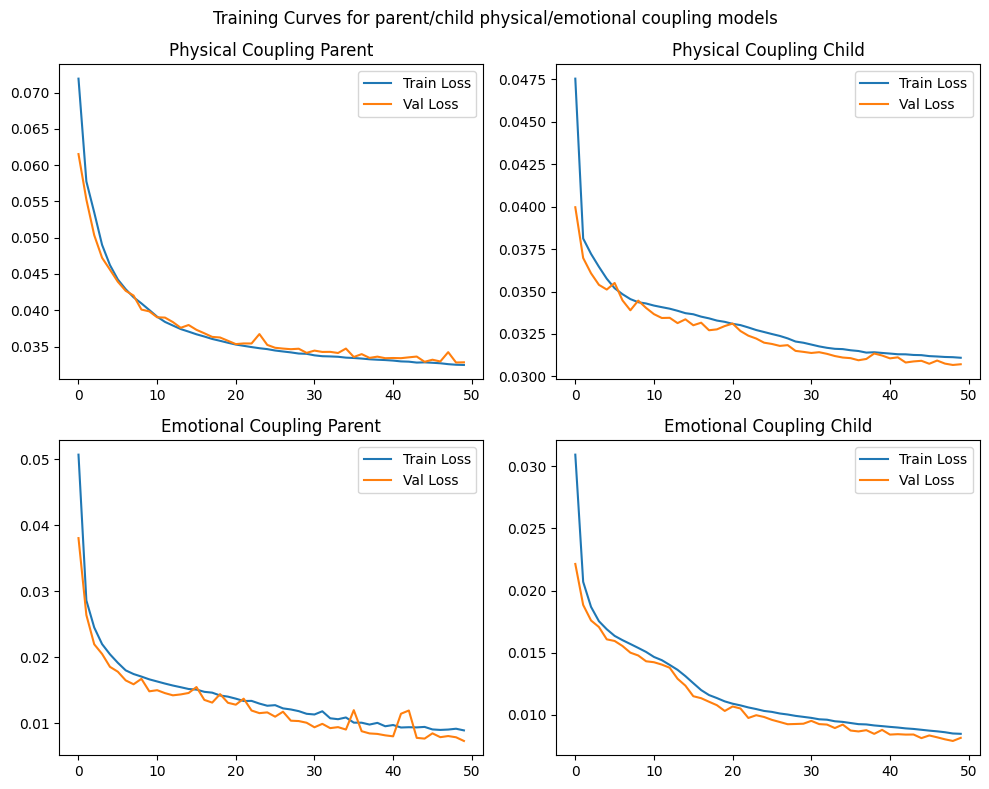

In [13]:
# Plotting training curves
fig, axs = plt.subplots(2,2, figsize = (10,8))
axs[0,0].plot(p_coupling_parent_losses, label = 'Train Loss')
axs[0,0].plot(p_coupling_parent_val_losses, label = 'Val Loss')
axs[0,0].set_title('Physical Coupling Parent')
axs[0,0].legend()
axs[0,1].plot(p_coupling_child_losses, label = 'Train Loss')
axs[0,1].plot(p_coupling_child_val_losses, label = 'Val Loss')
axs[0,1].set_title('Physical Coupling Child')
axs[0,1].legend()
axs[1,0].plot(e_coupling_parent_losses, label = 'Train Loss')
axs[1,0].plot(e_coupling_parent_val_losses, label = 'Val Loss')
axs[1,0].set_title('Emotional Coupling Parent')
axs[1,0].legend()
axs[1,1].plot(e_coupling_child_losses, label = 'Train Loss')
axs[1,1].plot(e_coupling_child_val_losses, label = 'Val Loss')
axs[1,1].set_title('Emotional Coupling Child')
axs[1,1].legend()
fig.suptitle('Training Curves for parent/child physical/emotional coupling models')
plt.tight_layout()
plt.show()

## Evaluation

Evaluating physical distance network


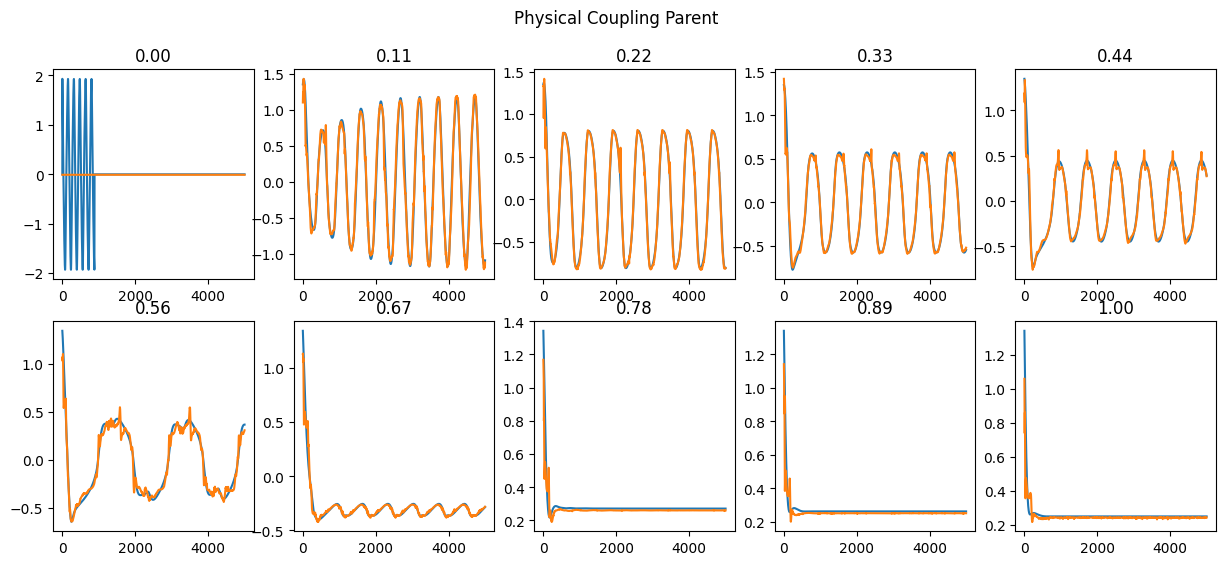

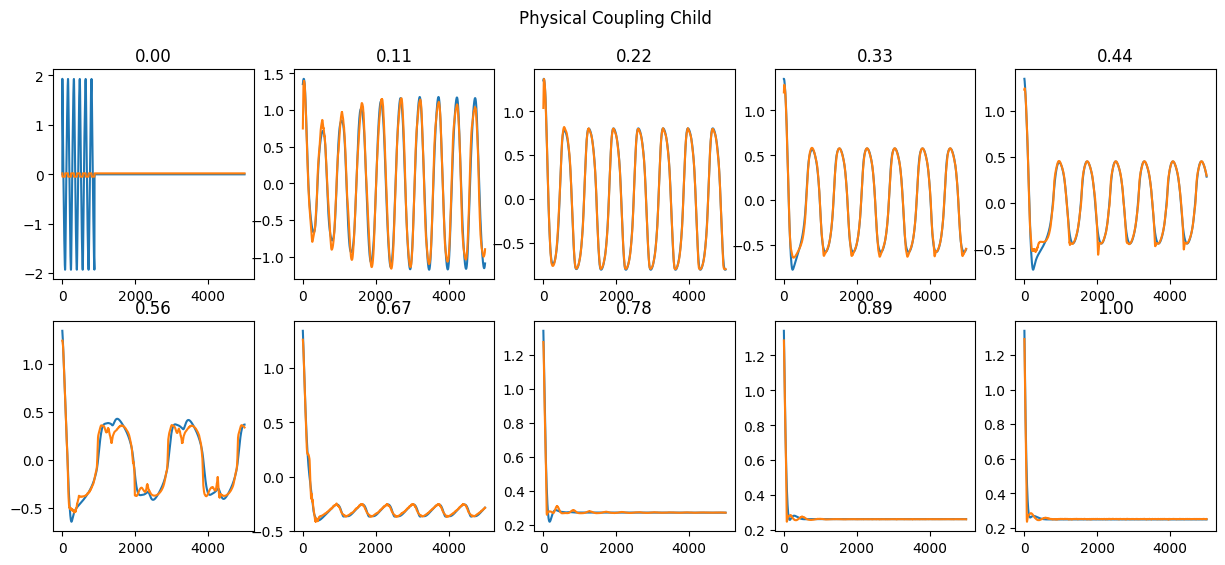

Evaluating emotional distance network


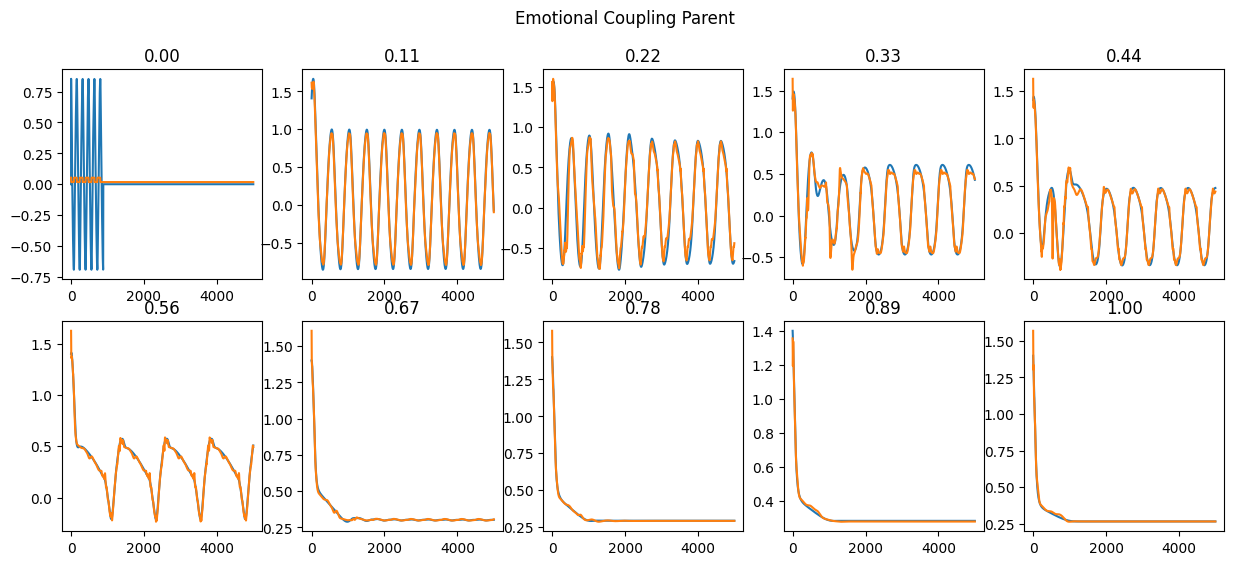

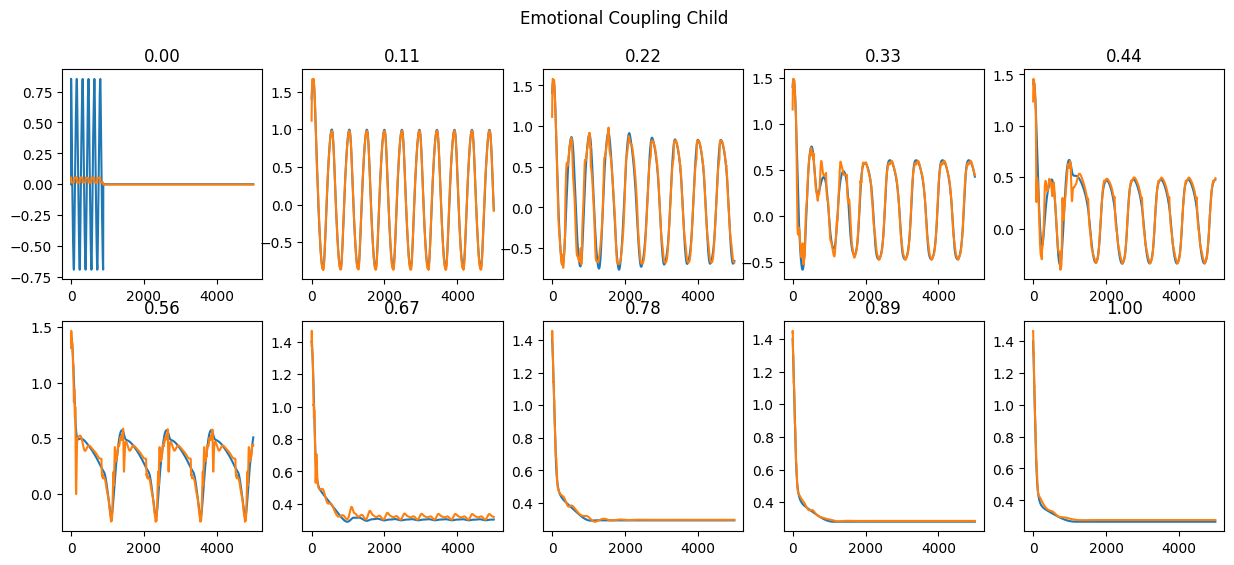

In [14]:
def evaluate_model( model, test_dataset, device = 'cpu', title = "" ):
    model.eval()
    T=10000
    D_in = test_dataset.X.shape[-1]
    X = np.zeros((len(ambivalences), T, D_in))
    Y = np.zeros((len(ambivalences), T, 1))
    Y_pred = np.zeros((len(ambivalences), T, 1))

    for i in range(len(ambivalences)):
        x, y = test_dataset[i]        # x: [5000,10], y: [5000,2]
        x = x.to(device)
        # x[:, -1] = torch.rand(( T-1))*0.5

        with torch.no_grad():
            outputs = model(x)        # outputs: [5000,2]

        X[i, :, :] = x.cpu().numpy()
        Y[i, :, :] = y.cpu().numpy()
        Y_pred[i, :, :] = outputs.cpu().numpy()

    x = X.reshape(-1, 10).transpose(1,0)
    y = Y.reshape(-1, 2).transpose(1,0)
    y_pred = Y_pred.reshape(-1, 2).transpose(1,0)

    fig, ax = plt.subplots(2, 5, figsize=(15, 6))
    for i in range(10):
        ax[i//5, i%5].plot(y[0,i*5000:min((i+1)*5000, len(y[0,:]))])
        ax[i//5, i%5].plot(y_pred[0, i*5000:min((i+1)*5000, y_pred.shape[1])])

        ax[i//5, i%5].set_title("{:.2f}".format(ambivalences[i]))
    fig.suptitle(title)
    plt.show()

print("Evaluating physical distance network")
evaluate_model( p_coupling_parent_NN, parent_physical_test_dataset, device = device, title = "Physical Coupling Parent")
evaluate_model( p_coupling_child_NN, child_physical_test_dataset, device = device, title = "Physical Coupling Child")
print("Evaluating emotional distance network")
evaluate_model( e_coupling_parent_NN, parent_emotional_test_dataset, device = device, title = "Emotional Coupling Parent")
evaluate_model( e_coupling_child_NN, child_emotional_test_dataset, device = device, title = "Emotional Coupling Child")

# Running the simulation with the models

{'Xc': array([[0.24073292, 0.22756323, 0.23749985, ..., 0.97121212, 0.94407066,
        0.97400414],
       [0.22923644, 0.20228168, 0.23058828, ..., 0.4765609 , 0.48934141,
        0.48734473]]), 'Xp': array([[-0.02594595, -0.04030536, -0.03964517, ...,  0.03625816,
         0.00625831,  0.02362631],
       [ 0.01506013,  0.04140035,  0.01140762, ..., -0.03836287,
        -0.03845836, -0.0629196 ]]), 'ambivalence': [0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3,

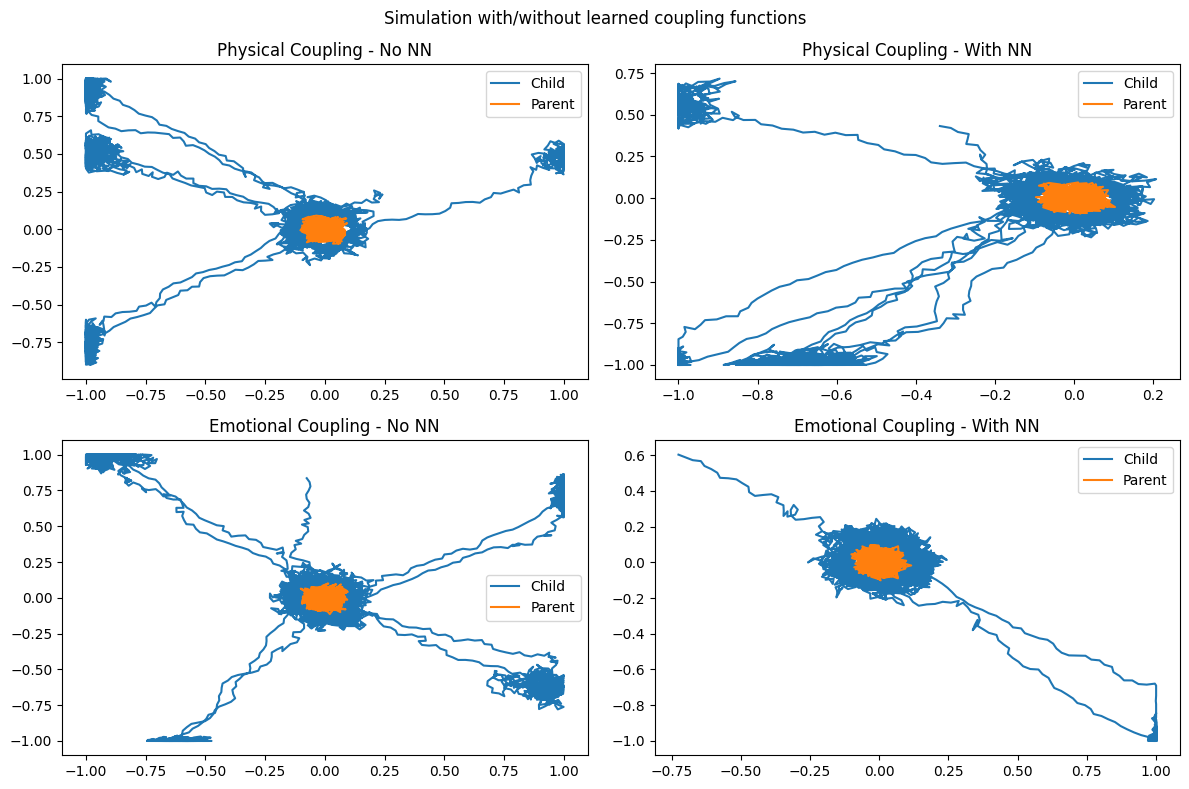

In [15]:
ambivalence = 0.3
avoidance = 0.3
T = 5000

data_physical = simulateSS(ambivalence, 0.0, T)
data_physical_coupling = simulateSS(ambivalence, 0.0, T, physical_parent_coupling = p_coupling_parent_NN,
                                  physical_child_coupling = p_coupling_child_NN)

data_emotional = simulateSS(0.0, avoidance, T)
data_emotional_coupling = simulateSS(0.0, avoidance, T, emotional_parent_coupling = e_coupling_parent_NN,
                                  emotional_child_coupling = e_coupling_child_NN)


fig, axs = plt.subplots(2,2, figsize = (12,8))
axs[0,0].plot(data_physical['Xc'][0,:], data_physical['Xc'][1,:], label = 'Child')
axs[0,0].plot(data_physical['Xp'][0,:], data_physical['Xp'][1,:], label = 'Parent')
axs[0,0].set_title('Physical Coupling - No NN')
axs[0,0].legend()
axs[0,1].plot(data_physical_coupling['Xc'][0,:], data_physical_coupling['Xc'][1,:], label = 'Child')
axs[0,1].plot(data_physical_coupling['Xp'][0,:], data_physical_coupling['Xp'][1,:], label = 'Parent')
axs[0,1].set_title('Physical Coupling - With NN')
axs[0,1].legend()
axs[1,0].plot(data_emotional['Xc'][0,:], data_emotional['Xc'][1,:], label = 'Child')
axs[1,0].plot(data_emotional['Xp'][0,:], data_emotional['Xp'][1,:], label = 'Parent')
axs[1,0].set_title('Emotional Coupling - No NN')
axs[1,0].legend()
axs[1,1].plot(data_emotional_coupling['Xc'][0,:], data_emotional_coupling['Xc'][1,:], label = 'Child')
axs[1,1].plot(data_emotional_coupling['Xp'][0,:], data_emotional_coupling['Xp'][1,:], label = 'Parent')
axs[1,1].set_title('Emotional Coupling - With NN')
axs[1,1].legend()
fig.suptitle('Simulation with/without learned coupling functions')
plt.tight_layout()
plt.show()
